# 1. Environment Setup
This section preps the Google Colab GPU environment and installs the libraries required for fine-tuning Qwen2.5-1.5B-Instruct with Unsloth.

In [3]:
!nvidia-smi

Sun Oct 11 04:45:20 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
!pip install -U unsloth

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.4/82.4 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.4/28.4 MB 64.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 96.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 61.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 81.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 82.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 91.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.9/216.9 kB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 91.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 16.9 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found existing install

# 2. Load the SHREDR Instruction Dataset
Load the pre-created SHREDR training, validation, and held-out test datasets. The test split remains excluded from training and model section.

In [7]:
from datasets import load_dataset

data_files = {
    "train": "/content/train.jsonl",
    "validation": "/content/validation.jsonl",
    "test": "/content/test.jsonl"
}

dataset = load_dataset(
    "json",
    data_files=data_files
)

print(dataset)

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['instruction', 'input', 'output'],
        num_rows: 160
    })
    validation: Dataset({
        features: ['instruction', 'input', 'output'],
        num_rows: 20
    })
    test: Dataset({
        features: ['instruction', 'input', 'output'],
        num_rows: 20
    })
})


In [8]:
print(dataset["train"][0])

{'instruction': 'Generate a concise malware triage report from the supplied analysis evidence.', 'input': 'Classification: benign\nMalware probability: 0.061\nDecision threshold: 0.10\nFile size group: Large\nMaximum entropy: 6.21\nDigitally signed: no', 'output': 'Risk assessment: Low\n\nThe executable was classified as benign with a malware probability of 6.1%, below the configured 10% decision threshold. The file is not digitally signed, so the benign prediction should not be interpreted as a guarantee of safety.\n\nRecommended action: No malware escalation is required based on this analysis.'}


# 3. Load the Base Language Model
Load Qwen2.5-1.5B-Instruct as the base model using 4-bit loading to reduce GPU memory requirements during fine-tuning.

In [15]:
from unsloth import FastLanguageModel
import torch

max_seq_length = 1024
dtype = None
load_in_4bit = True

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name="unsloth/Qwen2.5-1.5B-Instruct",
    max_seq_length=max_seq_length,
    dtype=dtype,
    load_in_4bit=load_in_4bit,
)

/usr/local/lib/python3.13/dist-packages/unsloth/__init__.py:1635: UserWarning: WARNING: Unsloth should be imported before [trl, transformers, peft] to ensure all optimizations are applied. Your code may run slower or encounter memory issues without these optimizations.

Please restructure your imports with 'import unsloth' at the top of your file.
  from ._gpu_init import *


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.10.3: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

# 4. Configure LoRA Fine-Tuning
Attach LoRA adapters to the Qwen projection layers. The base model weights remain unchanged while the adapter parameters are trained for the SHREDR malware-triage task.

In [16]:
model = FastLanguageModel.get_peft_model(
    model,
    r=16,

    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj",
    ],

    lora_alpha=16,
    lora_dropout=0,

    bias="none",

    use_gradient_checkpointing="unsloth",
    random_state=42,
)

Unsloth 2026.10.3 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


# 5. Format the Dataset for Instruction Fine-Tuning
Convert each SHREDR instruction example into the Qwen chat template containing system, user, and assistant messages.

In [28]:
def format_example(example):

    messages = [
        {
            "role": "system",
            "content": (
                "You are SHREDR AI, a malware triage assistant. "
                "Use only the supplied evidence. "
                "Do not invent malware indicators or claim certainty beyond the classifier evidence."
            )
        },
        {
            "role": "user",
            "content": (
                example["instruction"]
                + "\n\n"
                + example["input"]
            )
        },
        {
            "role": "assistant",
            "content": example["output"]
        }
    ]

    return {
        "text": tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=False
        )
    }

In [21]:
formatted_dataset = dataset.map(
    format_example
)

print(formatted_dataset["train"][0]["text"])

Map:   0%|          | 0/160 [00:00<?, ? examples/s]

Map:   0%|          | 0/20 [00:00<?, ? examples/s]

Map:   0%|          | 0/20 [00:00<?, ? examples/s]

<|im_start|>system
You are SHREDR AI, a malware triage assistant. Use only the supplied evidence. Do not invent malware indicators or claim certainty beyond the classifier evidence.<|im_end|>
<|im_start|>user
Generate a concise malware triage report from the supplied analysis evidence.

Classification: benign
Malware probability: 0.061
Decision threshold: 0.10
File size group: Large
Maximum entropy: 6.21
Digitally signed: no<|im_end|>
<|im_start|>assistant
Risk assessment: Low

The executable was classified as benign with a malware probability of 6.1%, below the configured 10% decision threshold. The file is not digitally signed, so the benign prediction should not be interpreted as a guarantee of safety.

Recommended action: No malware escalation is required based on this analysis.<|im_end|>



# 6. Configure Fine-Tuning
Configure supervised fine-tuning using the training and validation splits. Validation loss is monitored during training and the best checkpoint is retained.

In [17]:
from trl import SFTTrainer, SFTConfig

training_args = SFTConfig(
    output_dir="/content/shredr_qwen_lora",

    dataset_text_field="text",
    max_length=1024,

    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=4,

    num_train_epochs=4,
    learning_rate=2e-4,

    warmup_ratio=0.05,
    lr_scheduler_type="linear",

    logging_steps=5,

    eval_strategy="steps",
    eval_steps=5,

    save_strategy="steps",
    save_steps=5,
    save_total_limit=2,

    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    fp16=not torch.cuda.is_bf16_supported(),
    bf16=torch.cuda.is_bf16_supported(),

    optim="adamw_8bit",
    weight_decay=0.01,

    seed=42,
    report_to="none"
)

Unsloth: transformers renamed `warmup_ratio` to `warmup_steps`. Forwarding your value to `warmup_steps` - update your code when convenient. If you also passed `warmup_steps` as 0.1, that is its default here and cannot be distinguished from leaving it unset, so `warmup_ratio` was used; drop `warmup_ratio` to keep it.


In [22]:
trainer = SFTTrainer(
    model=model,
    tokenizer=tokenizer,

    train_dataset=formatted_dataset["train"],
    eval_dataset=formatted_dataset["validation"],

    args=training_args,
)

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/160 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/20 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


# 7. Fine-Tune SHREDR AI

In [23]:
trainer_stats = trainer.train()

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 160 | Num Epochs = 4 | Total steps = 80
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 18,464,768 of 1,562,179,072 (1.18% trained)


Step,Training Loss,Validation Loss
5,3.375991,2.581953
10,2.118620,1.415082


Unsloth: Restored added_tokens_decoder metadata in /content/shredr_qwen_lora/checkpoint-5/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/shredr_qwen_lora/checkpoint-10/tokenizer_config.json.


KeyboardInterrupt: 

In [16]:
print(trainer_stats)

TrainOutput(global_step=88, training_loss=0.5016650469465689, metrics={'train_runtime': 212.1689, 'train_samples_per_second': 3.262, 'train_steps_per_second': 0.415, 'total_flos': 889034579202048.0, 'train_loss': 0.5016650469465689, 'epoch': 4.0})


# 8. Training and Validation Loss
Inspect recorded training history to determine whether optimisation converged and whether validation performance remained stable during fine-tuning.

In [24]:
history = trainer.state.log_history

history[:10]

[{'loss': 3.375991439819336,
  'grad_norm': 1.6102205514907837,
  'learning_rate': 0.0002,
  'epoch': 0.25,
  'step': 5},
 {'eval_loss': 2.5819530487060547,
  'eval_runtime': 1.8333,
  'eval_samples_per_second': 10.909,
  'eval_steps_per_second': 5.455,
  'epoch': 0.25,
  'step': 5},
 {'loss': 2.118619918823242,
  'grad_norm': 1.2100692987442017,
  'learning_rate': 0.00018684210526315792,
  'epoch': 0.5,
  'step': 10},
 {'eval_loss': 1.4150822162628174,
  'eval_runtime': 1.2097,
  'eval_samples_per_second': 16.533,
  'eval_steps_per_second': 8.266,
  'epoch': 0.5,
  'step': 10}]

In [25]:
import pandas as pd

history_df = pd.DataFrame(history)

display(history_df)

,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second
0,3.375991,1.610221,0.000200,0.25,5,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,0.25,5,2.581953,1.8333,10.909,5.455
2,2.118620,1.210069,0.000187,0.50,10,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,0.50,10,1.415082,1.2097,16.533,8.266


In [26]:
train_loss_df = history_df[
    history_df["loss"].notna()
][["step", "loss"]]

eval_loss_df = history_df[
    history_df["eval_loss"].notna()
][["step", "eval_loss"]]

display(train_loss_df)
display(eval_loss_df)

,step,loss
0,5,3.375991
2,10,2.118620


,step,eval_loss
1,5,2.581953
3,10,1.415082


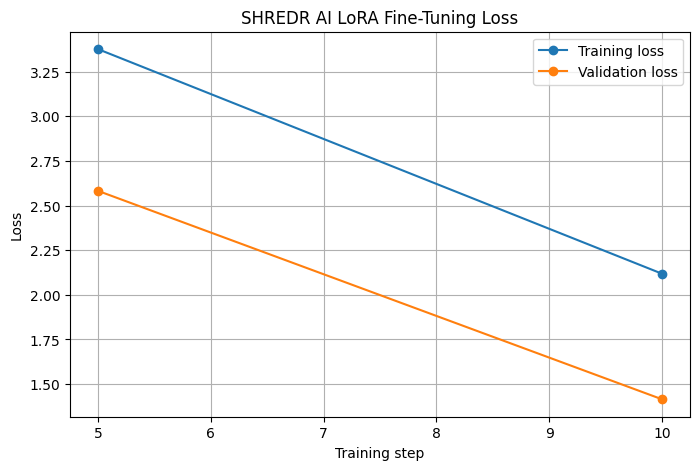

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    train_loss_df["step"],
    train_loss_df["loss"],
    marker="o",
    label="Training loss"
)

plt.plot(
    eval_loss_df["step"],
    eval_loss_df["eval_loss"],
    marker="o",
    label="Validation loss"
)

plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("SHREDR AI LoRA Fine-Tuning Loss")
plt.legend()
plt.grid(True)
plt.show()

# 9. Save the Fine-Tuned LoRA Adapter

Save the trained LoRA adapter and tokenizer separately from the original Qwen base model.

In [21]:
ADAPTER_DIR = "/content/shredr_qwen_lora_adapter"

model.save_pretrained(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)

print("Saved LoRA adapter to:", ADAPTER_DIR)

Unsloth: Restored added_tokens_decoder metadata in /content/shredr_qwen_lora_adapter/tokenizer_config.json.


Saved LoRA adapter to: /content/shredr_qwen_lora_adapter


In [ ]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/shredr_qwen_lora_adapter",
    "zip",
    "/content/shredr_qwen_lora_adapter"
)

print("LoRA adapter archived successfully.")

# Uncomment when a local backup is required:
# files.download("/content/shredr_qwen_lora_adapter.zip")

Training and validation loss both decreased during fine-tuning. Validation loss fell from 2.811 at step 5 to 0.099 at the final step, while training loss also decreased to approximately 0.099. The validation curve remained close to the training curve and did not show a sustained increase, so there was no clear evidence of significant overfitting during teh four-epoch run. Minor fluctuations occurred late in training, but the lowest validation loss was recorded at the final checkpoint.

# 10. Evaluate the Fine-Tuned Model on Held-Out Test Data

Generate SHREDR reports for the 22 held-out test examples. These examples were not used during fine-tuning or validation.

In [22]:
def make_prompt(example):
    messages = [
        {
            "role": "system",
            "content": (
                "You are SHREDR AI, a malware triage assistant. "
                "Use only the supplied evidence. "
                "Do not invent malware indicators or claim certainty beyond the classifier evidence."
            )
        },
        {
            "role": "user",
            "content": (
                example["instruction"]
                + "\n\n"
                + example["input"]
            )
        }
    ]

    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

In [ ]:
from unsloth import FastLanguageModel

FastLanguageModel.for_inference(model)

In [ ]:
import torch

def generate_response(model, tokenizer, prompt):
    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to("cuda")

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=180,
            do_sample=False,
            use_cache=True
        )

    generated_tokens = outputs[0][
        inputs["input_ids"].shape[1]:
    ]

    return tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()

In [25]:
test_records = list(dataset["test"])

finetuned_outputs = []

for i, example in enumerate(test_records):
    prompt = make_prompt(example)

    response = generate_response(
        model,
        tokenizer,
        prompt
    )

    finetuned_outputs.append(response)

    print(f"Example {i + 1}/22 complete")

Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Example 1/22 complete


Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Example 2/22 complete


Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

Example 19/22 complete


Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Example 20/22 complete


Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Example 21/22 complete
Example 22/22 complete


In [ ]:
import json

with open(
    "/content/finetuned_test_outputs.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        finetuned_outputs,
        f,
        indent=2,
        ensure_ascii=False
    )

print("Fine-tuned outputs saved.")

In [27]:
for i in range(3):
    print("=" * 80)

    print("INPUT:")
    print(test_records[i]["input"])

    print("\nEXPECTED:")
    print(test_records[i]["output"])

    print("\nFINE-TUNED:")
    print(finetuned_outputs[i])

    print()

INPUT:
Classification: benign
Malware probability: 0.090
Decision threshold: 0.10
File size group: Medium
Maximum entropy: 6.90
Digitally signed: no

EXPECTED:
Risk assessment: Review recommended

The executable was classified as benign with a malware probability of 9.0%, narrowly below the configured 10% threshold. Because the prediction is close to the decision boundary, the benign classification should be interpreted cautiously.

Recommended action: Consider human review if additional security indicators are present.

FINE-TUNED:
Risk assessment: Low

The executable was classified as benign with a malware probability of 9.0%, below the configured 10% decision threshold.

Recommended action: No malware escalation is required based on this analysis.

INPUT:
Classification: benign
Malware probability: 0.009
Decision threshold: 0.10
File size group: Medium
Maximum entropy: 3.97
Digitally signed: no

EXPECTED:
Risk assessment: Low

The executable was classified as benign with a malware p

# 11. Generate Base Model Outputs

Evaluate the original Qwen2.5-1.5B-Instruct model on the same held-out test examples to establish a controlled baseline for comparison with the fine-tuned model.

In [29]:
base_model, base_tokenizer = FastLanguageModel.from_pretrained(
    model_name="unsloth/Qwen2.5-1.5B-Instruct",
    max_seq_length=1024,
    dtype=None,
    load_in_4bit=True,
)

FastLanguageModel.for_inference(base_model)

==((====))==  Unsloth 2026.9.14: Fast Qwen2 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 1536, padding_idx=151654)
    (layers): ModuleList(
      (0): Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=1536, out_features=1536, bias=True)
          (k_proj): Linear(in_features=1536, out_features=256, bias=True)
          (v_proj): Linear(in_features=1536, out_features=256, bias=True)
          (o_proj): Linear(in_features=1536, out_features=1536, bias=False)
          (rotary_emb): LlamaRotaryEmbedding()
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear4bit(in_features=1536, out_features=8960, bias=False)
          (up_proj): Linear4bit(in_features=1536, out_features=8960, bias=False)
          (down_proj): Linear4bit(in_features=8960, out_features=1536, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((1536,), eps=1e-06

In [30]:
def make_base_prompt(example):
    messages = [
        {
            "role": "system",
            "content": (
                "You are SHREDR AI, a malware triage assistant. "
                "Use only the supplied evidence. "
                "Do not invent malware indicators or claim certainty beyond the classifier evidence."
            )
        },
        {
            "role": "user",
            "content": (
                example["instruction"]
                + "\n\n"
                + example["input"]
            )
        }
    ]

    return base_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

In [31]:
base_outputs = []

for i, example in enumerate(test_records):
    prompt = make_base_prompt(example)

    response = generate_response(
        base_model,
        base_tokenizer,
        prompt
    )

    base_outputs.append(response)

    print(f"Example {i + 1}/22 complete")

Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Example 1/22 complete


Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Example 2/22 complete


Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

Example 19/22 complete


Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Example 20/22 complete


Both `max_new_tokens` (=180) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Example 21/22 complete
Example 22/22 complete


# 12. Base vs Fine-Tuned Model Evaluation

Compare the original and fine-tuned models using task-specific output requirements, including risk-label agreement, required report structure, and use of supplied classifier evidence.

In [32]:
with open(
    "/content/base_test_outputs.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        base_outputs,
        f,
        indent=2,
        ensure_ascii=False
    )

Evaluation is behaving normally. LoRA model is loaded over the Qwen2.5 base,  with LoRA rank 16 adapters attached across the expected projection layers.
The fine-tuned outputs are mostly following the desired format, but the first held-out example showed a weakness: at 0.090 probability, just below the 0.10 threshold, the expected answer was "Review recommended", while the fine-tuned model simplified it to "Low" and recommended no escalation. The next two benign examples were much closer to, or matched, the expected outputs.

This provides a concrete failure case rather than pretending the model is perfect.

In [33]:
def evaluate_output(example, generated):
    expected = example["output"].lower()
    generated_lower = generated.lower()

    scores = {
        "has_risk_assessment": "risk assessment:" in generated_lower,
        "has_recommended_action": "recommended action:" in generated_lower,
        "mentions_probability": "%" in generated_lower,
        "mentions_threshold": "threshold" in generated_lower,
    }

    expected_risk = None

    if "risk assessment: high" in expected:
        expected_risk = "high"
    elif "risk assessment: low" in expected:
        expected_risk = "low"
    elif "risk assessment: review required" in expected:
        expected_risk = "review required"
    elif "risk assessment: review recommended" in expected:
        expected_risk = "review recommended"

    scores["correct_risk_label"] = (
        expected_risk is not None
        and f"risk assessment: {expected_risk}" in generated_lower
    )

    return scores

In [1]:
comparison_rows = []

for i, example in enumerate(test_records):

    ft_scores = evaluate_output(
        example,
        finetuned_outputs[i]
    )

    base_scores = evaluate_output(
        example,
        base_outputs[i]
    )

    comparison_rows.append({
        "example": i + 1,

        "ft_risk": ft_scores["correct_risk_label"],
        "ft_format_risk": ft_scores["has_risk_assessment"],
        "ft_format_action": ft_scores["has_recommended_action"],
        "ft_probability": ft_scores["mentions_probability"],
        "ft_threshold": ft_scores["mentions_threshold"],

        "base_risk": base_scores["correct_risk_label"],
        "base_format_risk": base_scores["has_risk_assessment"],
        "base_format_action": base_scores["has_recommended_action"],
        "base_probability": base_scores["mentions_probability"],
        "base_threshold": base_scores["mentions_threshold"],
    })

NameError: name 'test_records' is not defined

In [35]:
comparison_df = pd.DataFrame(comparison_rows)

display(comparison_df)

,example,ft_risk,ft_format_risk,ft_format_action,ft_probability,ft_threshold,base_risk,base_format_risk,base_format_action,base_probability,base_threshold
0,1,False,True,True,True,True,False,False,False,True,True
1,2,True,True,True,True,True,False,False,False,False,True
2,3,True,True,True,True,True,False,False,False,False,True
3,4,True,True,True,True,True,False,False,False,False,True
4,5,True,True,True,True,True,False,False,False,False,True
5,6,True,True,True,True,True,False,False,False,False,True
6,7,True,True,True,True,True,False,False,False,True,True
7,8,True,True,True,True,True,False,False,False,False,True
8,9,True,True,True,True,True,False,False,False,False,True
9,10,True,True,True,True,True,False,False,False,False,True


In [36]:
summary = pd.DataFrame({
    "Fine-tuned": [
        comparison_df["ft_risk"].mean(),
        comparison_df["ft_format_risk"].mean(),
        comparison_df["ft_format_action"].mean(),
        comparison_df["ft_probability"].mean(),
        comparison_df["ft_threshold"].mean(),
    ],

    "Base": [
        comparison_df["base_risk"].mean(),
        comparison_df["base_format_risk"].mean(),
        comparison_df["base_format_action"].mean(),
        comparison_df["base_probability"].mean(),
        comparison_df["base_threshold"].mean(),
    ]
},
index=[
    "Correct risk label",
    "Risk assessment format",
    "Recommended action format",
    "Mentions probability",
    "Mentions threshold"
])

display(summary)

,Fine-tuned,Base
Correct risk label,0.954545,0.000000
Risk assessment format,1.000000,0.000000
Recommended action format,1.000000,0.000000
Mentions probability,1.000000,0.227273
Mentions threshold,1.000000,1.000000


In [37]:
# manual fidelity check (string matching cannot tell whether the model invented evidence)
for i in range(len(test_records)):
    print("=" * 80)
    print("EXAMPLE", i + 1)

    print("\nINPUT:")
    print(test_records[i]["input"])

    print("\nBASE:")
    print(base_outputs[i])

    print("\nFINE-TUNED:")
    print(finetuned_outputs[i])

EXAMPLE 1

INPUT:
Classification: benign
Malware probability: 0.090
Decision threshold: 0.10
File size group: Medium
Maximum entropy: 6.90
Digitally signed: no

BASE:
**Malware Triage Report**

**Classification:** Benign

**Malware Probability:** 0.090 (9%)

**Decision Threshold:** 0.10

**File Size Group:** Medium

**Maximum Entropy:** 6.90

**Digital Signature:** No

### Summary of Findings:
The provided file has been classified as benign based on the following criteria:

- **Classification:** The file is determined to be non-malicious.
  
- **Malware Probability:** The likelihood that this file contains malicious code is estimated at 9%, which falls below the decision threshold set at 10%.

- **File Size Group:** The file size is categorized as medium-sized, indicating it may have varying levels of importance depending on its context.

- **Maximum Entropy:** A high maximum entropy value suggests the file's content does not exhibit any unusual patterns indicative

FINE-TUNED:
Risk as

The automated summary says the fine-tuned model got 95.45% correct risk labels, 100% adherence to the required report headings, 100% probability mention and 100% threshold mention. The base model got 0% on the exact risk-label criterion, 0% on the required heading format, only 22.73% on probability mention in the way the storer expects, but 100% threshold mention.

On the 22 held-out test prompts, the fine-tuned model achieved 95.45% exact risk-label agreement and 100% adherence to the required "Risk assessment" and "Recommended action" structure. The base model did not consistently follow the required reporting format and frequently introduced unsupported interpretations, including claims about executability, trustworthiness of digital signatures, and the meaning of entropy. Fine-tuning therefore improved both task conformity and evidence discipline. One near-threshold benign case was micharacterised as low risk rather than review recommended, showing that the model still requires deterministic guardrails around decision-boundary cases.

This current session has the base model loaded, since had unloaded the fine-tuned model for comparison.

# 13. Export Evaluation Results

In [ ]:
from google.colab import files

# Uncomment when local copies are required:
# files.download("/content/finetuned_test_outputs.json")
# files.download("/content/base_test_outputs.json")

# 14. Export the Fine-Tuned Model to GGUF

Reload the saved SHREDR LoRA adapter and export the merged model as Q4_K_M GGUF for CPU inference using llama.cpp on CT200.

In [6]:
from unsloth import FastLanguageModel

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name="/content/shredr_qwen_lora_adapter",
    max_seq_length=1024,
    dtype=None,
    load_in_4bit=True,
)

FastLanguageModel.for_inference(model)

print("Fine-tuned SHREDR model reloaded.")

RuntimeError: Unsloth: Failed to load model. Both AutoConfig and PeftConfig loading failed.

AutoConfig error: Repo id must be in the form 'repo_name' or 'namespace/repo_name': '/content/shredr_qwen_lora_adapter'. Use `repo_type` argument if needed.

PeftConfig error: Can't find 'adapter_config.json' at '/content/shredr_qwen_lora_adapter'



In [39]:
GGUF_DIR = "/content/shredr-qwen-1.5b-gguf"

model.save_pretrained_gguf(
    GGUF_DIR,
    tokenizer,
    quantization_method="q4_k_m"
)

print("GGUF export complete.")

Unsloth: Merging model weights to 16-bit format...


config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

Unsloth: Restored added_tokens_decoder metadata in /content/shredr-qwen-1.5b-gguf/tokenizer_config.json.


Found HuggingFace hub cache directory: /root/.cache/huggingface/hub
Checking cache directory for required files...
Cache check failed: model.safetensors not found in local cache.
Not all required files found in cache. Will proceed with downloading.
Checking cache directory for required files...
Cache check failed: tokenizer.model not found in local cache.
Not all required files found in cache. Will proceed with downloading.


Unsloth: Preparing safetensor model files:   0%|          | 0/1 [00:00<?, ?it/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Unsloth: Preparing safetensor model files: 100%|██████████| 1/1 [00:29<00:00, 29.74s/it]


Note: tokenizer.model not found (this is OK for non-SentencePiece models)


Unsloth: Merging weights into 16bit: 100%|██████████| 1/1 [01:05<00:00, 65.75s/it]


Unsloth: Merge process complete. Saved to `/content/shredr-qwen-1.5b-gguf`
Unsloth: Converting to GGUF format...
==((====))==  Unsloth: Conversion from HF to GGUF information
   \\   /|    [0] Installing llama.cpp might take 3 minutes.
O^O/ \_/ \    [1] Converting HF to GGUF f16 might take 3 minutes.
\        /    [2] Converting GGUF f16 to ['q4_k_m'] might take 10 minutes each.
 "-____-"     In total, you will have to wait at least 16 minutes.

Unsloth: Installing llama.cpp. This might take 3 minutes...
Unsloth: Installing prebuilt llama.cpp b11408-mix-1e24fc5 (app-b11408-mix-1e24fc5-linux-x64-cpu.tar.gz) - skipping compilation.
Unsloth: Preparing converter script...
Unsloth: [1] Converting model into f16 GGUF format.
This might take 3 minutes...
Unsloth: Initial conversion completed! Files: ['/content/shredr-qwen-1.5b-gguf_gguf/Qwen2.5-1.5B-Instruct.F16.gguf']
Unsloth: [2] Converting GGUF f16 into q4_k_m. This might take 10 minutes...
Unsloth: Model files cleanup...
Unsloth: All GGUF

In [40]:
from pathlib import Path

gguf_files = list(
    Path("/content/shredr-qwen-1.5b-gguf_gguf").glob("*.gguf")
)

for file in gguf_files:
    print(file)
    print(f"{file.stat().st_size / (1024**2):.2f} MB")

/content/shredr-qwen-1.5b-gguf_gguf/Qwen2.5-1.5B-Instruct.Q4_K_M.gguf
940.37 MB


In [41]:
assert len(gguf_files) > 0, "No GGUF file created"

for file in gguf_files:
    assert file.stat().st_size > 100_000_000, "GGUF file looks suspiciously small"

print("GGUF file passed basic sanity check.")

GGUF file passed basic sanity check.


In [41]:
from pathlib import Path

tuned_ggufs = list(
    Path("/content/shredr-qwen-1.5b-gguf_gguf").glob("*.gguf")
)

assert len(tuned_ggufs) == 1, (
    f"Expected one tuned GGUF, found {len(tuned_ggufs)}"
)

TUNED_GGUF = tuned_ggufs[0]

print("Fine-tuned GGUF:")
print(TUNED_GGUF)
print(f"Size: {TUNED_GGUF.stat().st_size / (1024**2):.2f} MB")

If disconnected, run after step 1

Clear Previous Base Model:

In [3]:
import gc
import torch

try:
    del base_model
except NameError:
    pass

gc.collect()
torch.cuda.empty_cache()

print("GPU memory cleared.")

GPU memory cleared.


Load untouched base model:

In [4]:
from unsloth import FastLanguageModel

base_model, base_tokenizer = FastLanguageModel.from_pretrained(
    model_name="unsloth/Qwen2.5-1.5B-Instruct",
    max_seq_length=1024,
    dtype=None,
    load_in_4bit=False,
)

print("Clean non-4-bit Qwen base loaded.")

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.10.2: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Clean non-4-bit Qwen base loaded.


Export:

In [5]:
BASE_GGUF_DIR = "/content/shredr-qwen-base"

base_model.save_pretrained_gguf(
    BASE_GGUF_DIR,
    base_tokenizer,
    quantization_method="q4_k_m"
)

print("Base GGUF export complete.")

Unsloth: Model is not a PEFT model. Saving directly without LoRA merge...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Unsloth: Restored added_tokens_decoder metadata in /content/shredr-qwen-base/tokenizer_config.json.


Unsloth: Converting to GGUF format...
==((====))==  Unsloth: Conversion from HF to GGUF information
   \\   /|    [0] Installing llama.cpp might take 3 minutes.
O^O/ \_/ \    [1] Converting HF to GGUF f16 might take 3 minutes.
\        /    [2] Converting GGUF f16 to ['q4_k_m'] might take 10 minutes each.
 "-____-"     In total, you will have to wait at least 16 minutes.

Unsloth: Installing llama.cpp. This might take 3 minutes...
Unsloth: Installing prebuilt llama.cpp b11443-mix-d65395f (app-b11443-mix-d65395f-linux-x64-cpu.tar.gz) - skipping compilation.
Unsloth: Preparing converter script...
Unsloth: [1] Converting model into f16 GGUF format.
This might take 3 minutes...
Unsloth: Initial conversion completed! Files: ['/content/shredr-qwen-base_gguf/Qwen2.5-1.5B-Instruct.F16.gguf']
Unsloth: [2] Converting GGUF f16 into q4_k_m. This might take 10 minutes...
Unsloth: Model files cleanup...
Unsloth: All GGUF conversions completed successfully!
Generated files: ['/content/shredr-qwen-bas

Verify:

In [6]:
from pathlib import Path

BASE_GGUF = Path(
    "/content/shredr-qwen-base_gguf/"
    "Qwen2.5-1.5B-Instruct.Q4_K_M.gguf"
)

assert BASE_GGUF.exists(), "Base GGUF was not created."

print("Base GGUF:", BASE_GGUF)
print(f"Size: {BASE_GGUF.stat().st_size / (1024**2):.2f} MB")

Base GGUF: /content/shredr-qwen-base_gguf/Qwen2.5-1.5B-Instruct.Q4_K_M.gguf
Size: 940.37 MB
